# TCGA-KIRC: immune and inflammation expression features

## Aim

This notebook defines a biologically motivated immune/inflammation gene panel from the matched TCGA-KIRC expression cohort. I will inspect gene availability, expression distributions, and correlations before conducting any survival analyses.

In [2]:
# 04-01  Import packages and load analysis data 
#        from last 03 notebook endpoint

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

sns.set_theme(style="whitegrid", context="notebook")

clinical_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_matched_clinical_survival_data.csv"
)

zscore_file = (
    PROCESSED_DATA_DIR
    / "tcga_kirc_log2_tpm_zscore_protein_coding_by_patient.pkl.gz"
)

gene_annotation_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_analysis_gene_annotation.csv"
)

matched_clinical_data = pd.read_csv(clinical_file)
expression_zscore = pd.read_pickle(zscore_file)
gene_annotation = pd.read_csv(gene_annotation_file)

assert matched_clinical_data["patient_id"].tolist() == expression_zscore.columns.tolist()
assert gene_annotation["gene_id"].tolist() == expression_zscore.index.tolist()

print("Clinical patients:", len(matched_clinical_data))
print("Deaths:", matched_clinical_data["event_observed"].sum())
print("Standardized expression matrix:", expression_zscore.shape)
print("Annotated analysis genes:", len(gene_annotation))

Clinical patients: 518
Deaths: 171
Standardized expression matrix: (19524, 518)
Annotated analysis genes: 19524


## 04-02 Pre-specified immune/inflammation gene panel

I will examine 14 genes in three biologically defined groups:

- *Effector T-cell activity:* `CD8A`, `IFNG`, `GZMA`, `GZMB`, `PRF1`, and `EOMES`
- *Immune checkpoints:* `CD274`, `CTLA4`, and `TIGIT`
- *Myeloid inflammation:* `CXCL1`, `CXCL2`, `CXCL3`, `IL6`, and `PTGS2`

These groups were selected before survival modeling from a published ccRCC immune-signature study. They are expression markers, not direct measurements of immune-cell numbers. I will first check that every gene is present and inspect their expression patterns. [ref.]Ohe C, Yoshida T, Ikeda J, et al. Histologic-Based Tumor-Associated Immune Cells Status in Clear Cell Renal Cell Carcinoma Correlates with Gene Signatures Related to Cancer Immunity and Clinical Outcomes. Biomedicines. 2022;10(2):323. doi:10.3390/biomedicines10020323.
https://doi.org/10.3390/biomedicines10020323, https://www.mdpi.com/2227-9059/10/2/323

## 04-03 Define the immune/inflammation gene panel

In [4]:
# 04-03 Define the immune/inflammation gene panel

gene_panel = pd.DataFrame(
    {
        "gene_group": (
            ["Effector T-cell activity"] * 6
            + ["Immune checkpoint"] * 3
            + ["Myeloid inflammation"] * 5
        ),
        "gene_name": [
            "CD8A", "IFNG", "GZMA", "GZMB", "PRF1", "EOMES",
            "CD274", "CTLA4", "TIGIT",
            "CXCL1", "CXCL2", "CXCL3", "IL6", "PTGS2",
        ],
    }
)

display(gene_panel)
print("Genes in panel:", len(gene_panel))

,gene_group,gene_name
0,Effector T-cell activity,CD8A
1,Effector T-cell activity,IFNG
2,Effector T-cell activity,GZMA
3,Effector T-cell activity,GZMB
4,Effector T-cell activity,PRF1
5,Effector T-cell activity,EOMES
6,Immune checkpoint,CD274
7,Immune checkpoint,CTLA4
8,Immune checkpoint,TIGIT
9,Myeloid inflammation,CXCL1


Genes in panel: 14


## 04-04 Match panel genes to Ensembl IDs

In [5]:
# 04-04 Match panel genes to Ensembl IDs

panel_annotation = gene_panel.merge(
    gene_annotation[["gene_id", "gene_name"]],
    on="gene_name",
    how="left",
)

missing_panel_genes = panel_annotation[
    panel_annotation["gene_id"].isna()
]["gene_name"].tolist()

assert len(panel_annotation) == len(gene_panel)
assert len(missing_panel_genes) == 0

panel_annotation = panel_annotation[
    ["gene_group", "gene_name", "gene_id"]
]

display(panel_annotation)

print("Panel genes found:", len(panel_annotation))
print("Missing panel genes:", missing_panel_genes)

,gene_group,gene_name,gene_id
0,Effector T-cell activity,CD8A,ENSG00000153563.16
1,Effector T-cell activity,IFNG,ENSG00000111537.5
2,Effector T-cell activity,GZMA,ENSG00000145649.8
3,Effector T-cell activity,GZMB,ENSG00000100453.13
4,Effector T-cell activity,PRF1,ENSG00000180644.8
5,Effector T-cell activity,EOMES,ENSG00000163508.13
6,Immune checkpoint,CD274,ENSG00000120217.14
7,Immune checkpoint,CTLA4,ENSG00000163599.17
8,Immune checkpoint,TIGIT,ENSG00000181847.12
9,Myeloid inflammation,CXCL1,ENSG00000163739.5


Panel genes found: 14
Missing panel genes: []


## 04-05 Extract standardized expression for the panel

In [6]:
# 04-05 Extract standardized expression for the panel

panel_gene_ids = panel_annotation["gene_id"].tolist()

panel_expression_zscore = expression_zscore.loc[panel_gene_ids].copy()

panel_expression_zscore.index = panel_annotation["gene_name"].tolist()

print("Panel expression matrix shape:", panel_expression_zscore.shape)

display(
    panel_expression_zscore.T.describe().loc[
        ["mean", "std", "min", "max"]
    ].round(2)
)

Panel expression matrix shape: (14, 518)


,CD8A,IFNG,GZMA,GZMB,PRF1,EOMES,CD274,CTLA4,TIGIT,CXCL1,CXCL2,CXCL3,IL6,PTGS2
mean,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.73,-1.13,-3.47,-3.23,-3.95,-1.91,-2.54,-1.64,-1.87,-1.72,-2.31,-1.36,-1.15,-1.46
max,2.61,4.64,2.66,3.41,2.37,2.99,6.31,3.27,2.92,3.85,3.23,5.53,4.68,5.29


## 04-06 Loading log-transformed expression for plotting

In [7]:
# 04-06 Load log-transformed expression for plotting

log2_tpm_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_log2_tpm_protein_coding_by_patient.pkl.gz"
)

expression_log2_tpm = pd.read_pickle(log2_tpm_file)

panel_expression_log2 = expression_log2_tpm.loc[panel_gene_ids].copy()

panel_expression_log2.index = panel_annotation["gene_name"].tolist()

panel_expression_long = (
    panel_expression_log2
    .T
    .melt(var_name="gene_name", value_name="log2_tpm")
    .merge(gene_panel, on="gene_name", how="left")
)

display(
    panel_expression_long.groupby("gene_name")["log2_tpm"]
    .describe()[["mean", "std", "min", "max"]]
    .round(2)
)

,mean,std,min,max
gene_name,,,,
CD274,2.54,0.87,0.33,8.02
CD8A,4.59,1.59,0.25,8.74
CTLA4,1.58,0.96,0.00,4.73
CXCL1,3.21,1.84,0.04,10.31
CXCL2,3.82,1.59,0.16,8.94
CXCL3,1.14,0.84,0.00,5.75
EOMES,2.39,1.21,0.09,6.00
GZMA,5.56,1.29,1.08,9.00
GZMB,3.56,1.02,0.27,7.04


## 04-07 its time to visualize expression distributions and gene correlations

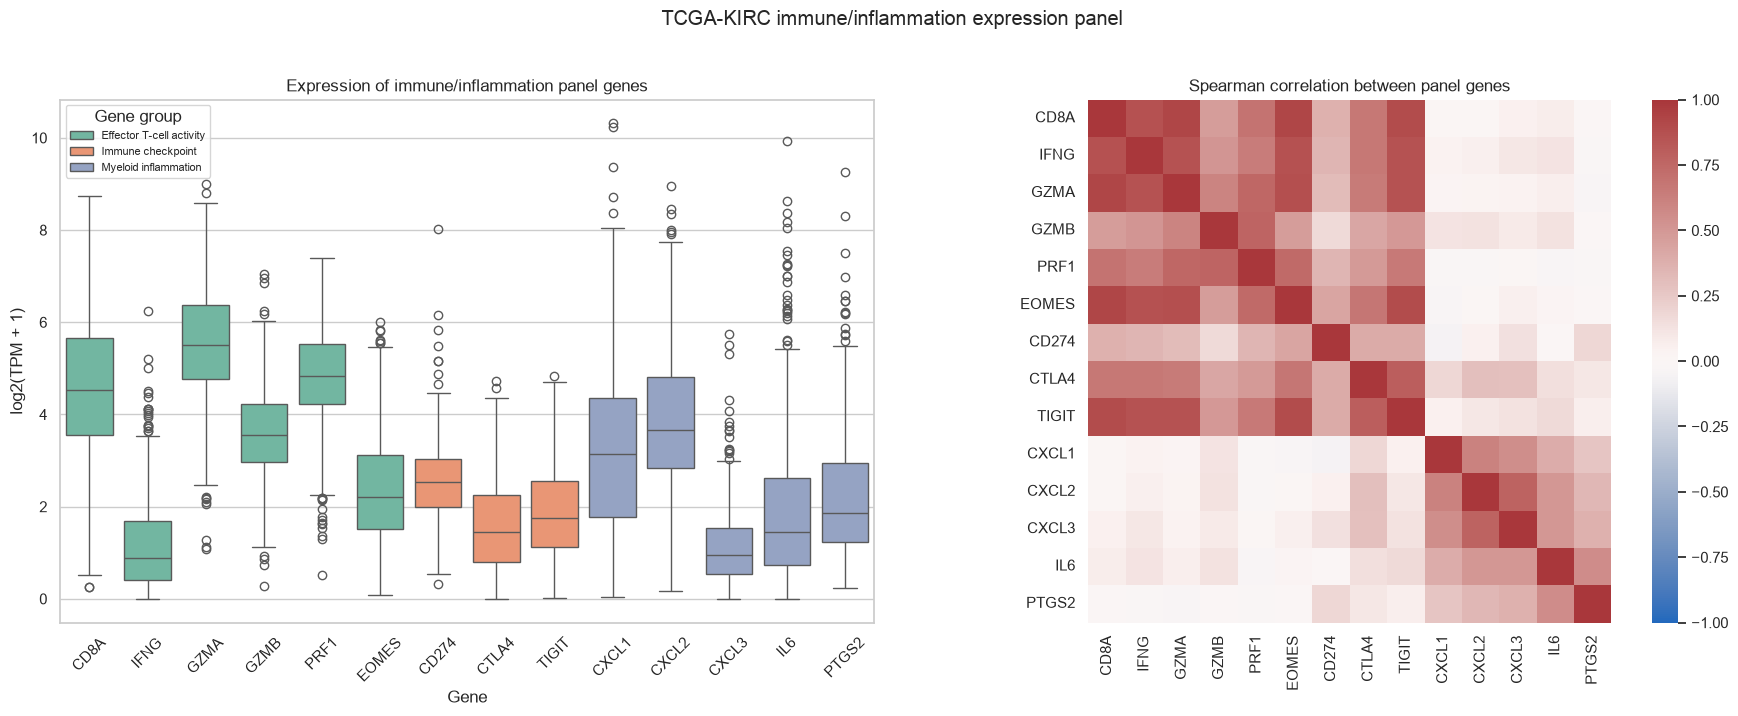

Figure saved as: figure_06_immune_inflammation_panel_qc.png


In [8]:
# 04-07 Trying to visualize expression distributions and gene correlations

gene_correlations = panel_expression_zscore.T.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.boxplot(
    data=panel_expression_long,
    x="gene_name",
    y="log2_tpm",
    hue="gene_group",
    palette="Set2",
    ax=axes[0],
)

axes[0].set_title("Expression of immune/inflammation panel genes")
axes[0].set_xlabel("Gene")
axes[0].set_ylabel("log2(TPM + 1)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Gene group", fontsize=8)

sns.heatmap(
    gene_correlations,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1],
)

axes[1].set_title("Spearman correlation between panel genes")

fig.suptitle("TCGA-KIRC immune/inflammation expression panel", y=1.02)
plt.tight_layout()

figure_file = (
    RESULTS_DIR / "figures" / "figure_06_immune_inflammation_panel_qc.png"
)

fig.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {figure_file.name}")

Figure shows : 
a) Effector T-cell genes cluster strongly with one another.
b) Checkpoint genes correlate with the effector group, consistent with an immune-active/exhausted ccRCC environment.
c) The five myeloid-inflammation genes cluster separately.

## 04-08  Creating immune/inflammation signature scores

In [9]:
# 04-08 Creating immune/inflammation signature scores

signature_scores = pd.DataFrame(
    index=panel_expression_zscore.columns
)

signature_scores["effector_t_cell_score"] = (
    panel_expression_zscore.loc[
        ["CD8A", "IFNG", "GZMA", "GZMB", "PRF1", "EOMES"]
    ].mean(axis=0)
)

signature_scores["immune_checkpoint_score"] = (
    panel_expression_zscore.loc[
        ["CD274", "CTLA4", "TIGIT"]
    ].mean(axis=0)
)

signature_scores["myeloid_inflammation_score"] = (
    panel_expression_zscore.loc[
        ["CXCL1", "CXCL2", "CXCL3", "IL6", "PTGS2"]
    ].mean(axis=0)
)

signature_scores.index.name = "patient_id"
signature_scores = signature_scores.reset_index()

signature_score_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_immune_inflammation_signature_scores.csv"
)

signature_scores.to_csv(signature_score_file, index=False)

display(signature_scores.describe().round(2))

print(f"Signature-score file saved as: {signature_score_file.name}")

,effector_t_cell_score,immune_checkpoint_score,myeloid_inflammation_score
count,518.00,518.00,518.00
mean,-0.00,0.00,-0.00
std,0.89,0.84,0.77
min,-2.66,-1.85,-1.50
25%,-0.59,-0.60,-0.54
50%,-0.10,-0.11,-0.08
75%,0.53,0.54,0.41
max,2.81,3.76,3.51


Signature-score file saved as: tcga_kirc_immune_inflammation_signature_scores.csv


## 04-09 Visualizing signature-score distributions and correlations

/var/folders/dy/g7qs6yvj71d5kt43gwgy2k3c0000gn/T/ipykernel_2164/2310224386.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


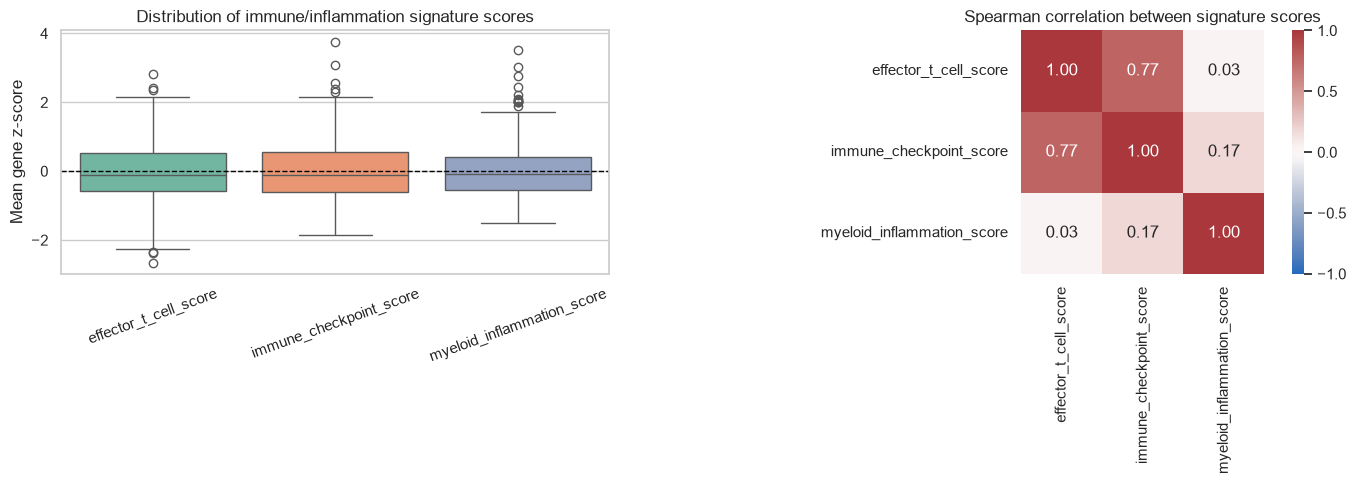

Figure saved as: figure_07_signature_score_distributions.png


In [10]:
# 04-09 trying to Visualize signature-score distributions and correlations

score_columns = [
    "effector_t_cell_score",
    "immune_checkpoint_score",
    "myeloid_inflammation_score",
]

signature_scores_long = signature_scores.melt(
    id_vars="patient_id",
    value_vars=score_columns,
    var_name="signature",
    value_name="score",
)

score_correlations = signature_scores[score_columns].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=signature_scores_long,
    x="signature",
    y="score",
    palette="Set2",
    ax=axes[0],
)

axes[0].axhline(0, color="black", linewidth=1, linestyle="--")
axes[0].set_title("Distribution of immune/inflammation signature scores")
axes[0].set_xlabel("")
axes[0].set_ylabel("Mean gene z-score")
axes[0].tick_params(axis="x", rotation=20)

sns.heatmap(
    score_correlations,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1],
)

axes[1].set_title("Spearman correlation between signature scores")

plt.tight_layout()

figure_file = (
    RESULTS_DIR / "figures" / "figure_07_signature_score_distributions.png"
)

fig.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {figure_file.name}")

# 04-10 Combining clinical data with signature scores

In [11]:
# 04-10 Combining clinical data with signature scores

clinical_signature_data = matched_clinical_data.merge(
    signature_scores,
    on="patient_id",
    how="inner",
    validate="one_to_one",
)

assert len(clinical_signature_data) == 518
assert clinical_signature_data["patient_id"].is_unique
assert clinical_signature_data[score_columns].notna().all().all()

clinical_signature_file = (
    PROCESSED_DATA_DIR
    / "tcga_kirc_clinical_immune_signature_analysis_data.csv"
)

clinical_signature_data.to_csv(clinical_signature_file, index=False)

print("Patients in clinical-signature dataset:", len(clinical_signature_data))
print("Deaths:", clinical_signature_data["event_observed"].sum())
print(f"Dataset saved as: {clinical_signature_file.name}")

Patients in clinical-signature dataset: 518
Deaths: 171
Dataset saved as: tcga_kirc_clinical_immune_signature_analysis_data.csv


04-11 
Save the panel definition

In [16]:
# 04-11 — Save the panel definition and its citation

panel_definition = panel_annotation.copy()

panel_definition["ref."] = (
   "https://www.mdpi.com/2227-9059/10/2/323"
)

panel_definition_file = (
    PROJECT_DIR / "docs" / "immune_inflammation_gene_panel.csv"
)

panel_definition.to_csv(panel_definition_file, index=False)

print(f"Panel-definition file saved as: {panel_definition_file.name}")
display(panel_definition)

Panel-definition file saved as: immune_inflammation_gene_panel.csv


,gene_group,gene_name,gene_id,ref.
0,Effector T-cell activity,CD8A,ENSG00000153563.16,https://www.mdpi.com/2227-9059/10/2/323
1,Effector T-cell activity,IFNG,ENSG00000111537.5,https://www.mdpi.com/2227-9059/10/2/323
2,Effector T-cell activity,GZMA,ENSG00000145649.8,https://www.mdpi.com/2227-9059/10/2/323
3,Effector T-cell activity,GZMB,ENSG00000100453.13,https://www.mdpi.com/2227-9059/10/2/323
4,Effector T-cell activity,PRF1,ENSG00000180644.8,https://www.mdpi.com/2227-9059/10/2/323
5,Effector T-cell activity,EOMES,ENSG00000163508.13,https://www.mdpi.com/2227-9059/10/2/323
6,Immune checkpoint,CD274,ENSG00000120217.14,https://www.mdpi.com/2227-9059/10/2/323
7,Immune checkpoint,CTLA4,ENSG00000163599.17,https://www.mdpi.com/2227-9059/10/2/323
8,Immune checkpoint,TIGIT,ENSG00000181847.12,https://www.mdpi.com/2227-9059/10/2/323
9,Myeloid inflammation,CXCL1,ENSG00000163739.5,https://www.mdpi.com/2227-9059/10/2/323


## 04-12 qc

In [17]:
# 04-12 qc

missing_values = clinical_signature_data[
    [
        "overall_survival_days",
        "event_observed",
        "effector_t_cell_score",
        "immune_checkpoint_score",
        "myeloid_inflammation_score",
    ]
].isna().sum()

print("Patients:", len(clinical_signature_data))
print("Deaths:", clinical_signature_data["event_observed"].sum())
print("Censored patients:", (clinical_signature_data["event_observed"] == 0).sum())

print("\nMissing values:")
display(missing_values.to_frame(name="missing_count"))

assert missing_values.sum() == 0

print("\n complete ")

Patients: 518
Deaths: 171
Censored patients: 347

Missing values:


,missing_count
overall_survival_days,0
event_observed,0
effector_t_cell_score,0
immune_checkpoint_score,0
myeloid_inflammation_score,0



 complete 


### Stage 04 summary

A pre-specified 14-gene immune/inflammation panel was defined from a published clear-cell renal cell carcinoma study. All genes were present in the matched TCGA-KIRC expression matrix.

We created three patient-level scores : effector T-cell activity, immune checkpoint activity, and myeloid inflammation (by averaging standardized expression values) for the genes in each group. The resulting complete dataset contains 518 patients and 171 deaths and is now will be used for survival analysis.